In [2]:
import pandas as pd
import numpy as np

data = {
    "Age": [18, 20, 22, 25, 30, 35],
    "Salary": [20000, 30000, 40000, 50000, 80000, 150000],
    "Experience": [1, 2, 3, 5, 8, 12]
}

df = pd.DataFrame(data)

print(df)

   Age  Salary  Experience
0   18   20000           1
1   20   30000           2
2   22   40000           3
3   25   50000           5
4   30   80000           8
5   35  150000          12


In [4]:
print("Minimum values:")
print(df.min())

print("\nMaximum values:")
print(df.max())

print("\nFeature ranges:")
print(df.max() - df.min())

Minimum values:
Age              18
Salary        20000
Experience        1
dtype: int64

Maximum values:
Age               35
Salary        150000
Experience        12
dtype: int64

Feature ranges:
Age               17
Salary        130000
Experience        11
dtype: int64


In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df_standardized = scaler.fit_transform(df)

df_standardized = pd.DataFrame(
    df_standardized,
    columns=df.columns
)

print(df_standardized)

        Age    Salary  Experience
0 -1.188891 -0.952424   -1.095270
1 -0.849208 -0.723842   -0.832405
2 -0.509525 -0.495261   -0.569540
3  0.000000 -0.266679   -0.043811
4  0.849208  0.419067    0.744784
5  1.698416  2.019139    1.796243


In [10]:
print("Mean after standardized: ")
print(df_standardized.mean())

print("\nStandard deviation after standardized: ")
print(df_standardized.std(ddof=0))

Mean after standardized: 
Age          -3.700743e-17
Salary        1.480297e-16
Experience   -7.401487e-17
dtype: float64

Standard deviation after standardized: 
Age           1.0
Salary        1.0
Experience    1.0
dtype: float64


In [12]:
from sklearn.preprocessing import MinMaxScaler

minmax_scaler = MinMaxScaler()

df_normalised = minmax_scaler.fit_transform(df)

df_normalised = pd.DataFrame(
    df_normalised,
    columns=df.columns
)

print(df_normalised)

        Age    Salary  Experience
0  0.000000  0.000000    0.000000
1  0.117647  0.076923    0.090909
2  0.235294  0.153846    0.181818
3  0.411765  0.230769    0.363636
4  0.705882  0.461538    0.636364
5  1.000000  1.000000    1.000000


In [14]:
from sklearn.preprocessing import RobustScaler

robust = RobustScaler()

df_robust = robust.fit_transform(df)

df_robust = pd.DataFrame(
    df_robust,
    columns=df.columns
)

print(df_robust)

        Age  Salary  Experience
0 -0.666667  -0.625        -0.6
1 -0.424242  -0.375        -0.4
2 -0.181818  -0.125        -0.2
3  0.181818   0.125         0.2
4  0.787879   0.875         0.8
5  1.393939   2.625         1.6


In [16]:
comparision = pd.concat(
    [
        df.add_suffix("_Original"),
        df_standardized.add_suffix("_Standard"),
        df_normalised.add_suffix("_MinMax"),
        df_robust.add_suffix("_Robust")
    ],
    axis=1
)

print(comparision.round(3))

   Age_Original  Salary_Original  Experience_Original  Age_Standard  \
0            18            20000                    1        -1.189   
1            20            30000                    2        -0.849   
2            22            40000                    3        -0.510   
3            25            50000                    5         0.000   
4            30            80000                    8         0.849   
5            35           150000                   12         1.698   

   Salary_Standard  Experience_Standard  Age_MinMax  Salary_MinMax  \
0           -0.952               -1.095       0.000          0.000   
1           -0.724               -0.832       0.118          0.077   
2           -0.495               -0.570       0.235          0.154   
3           -0.267               -0.044       0.412          0.231   
4            0.419                0.745       0.706          0.462   
5            2.019                1.796       1.000          1.000   

   Experien

In [18]:
df_outlier = df.copy()

df_outlier.loc[6] = [40, 1000000,15]

print(df_outlier)

   Age   Salary  Experience
0   18    20000           1
1   20    30000           2
2   22    40000           3
3   25    50000           5
4   30    80000           8
5   35   150000          12
6   40  1000000          15


In [20]:
standard_outlier = StandardScaler()
minmax_outlier = MinMaxScaler()
robust_outlier = RobustScaler()

standard_result = standard_outlier.fit_transform(df_outlier)
minmax_result = minmax_outlier.fit_transform(df_outlier)
robust_result = robust_outlier.fit_transform(df_outlier)

comparision_outlier = pd.DataFrame({
    "Salary_Original": df_outlier["Salary"],
    "StandardScaler": standard_result[:, 1],
    "MinMaxScaler": minmax_result[:, 1],
    "RobustScaler": robust_result[:, 1]
})

print(comparision_outlier.round(3))

   Salary_Original  StandardScaler  MinMaxScaler  RobustScaler
0            20000          -0.531         0.000        -0.375
1            30000          -0.501         0.010        -0.250
2            40000          -0.471         0.020        -0.125
3            50000          -0.440         0.031         0.000
4            80000          -0.350         0.061         0.375
5           150000          -0.138         0.133         1.250
6          1000000           2.431         1.000        11.875


In [23]:
df_log = df.copy()

df_log["Salary_log"] = np.log1p(df_log["Salary"])

print(df_log[["Salary", "Salary_log"]])

   Salary  Salary_log
0   20000    9.903538
1   30000   10.308986
2   40000   10.596660
3   50000   10.819798
4   80000   11.289794
5  150000   11.918397


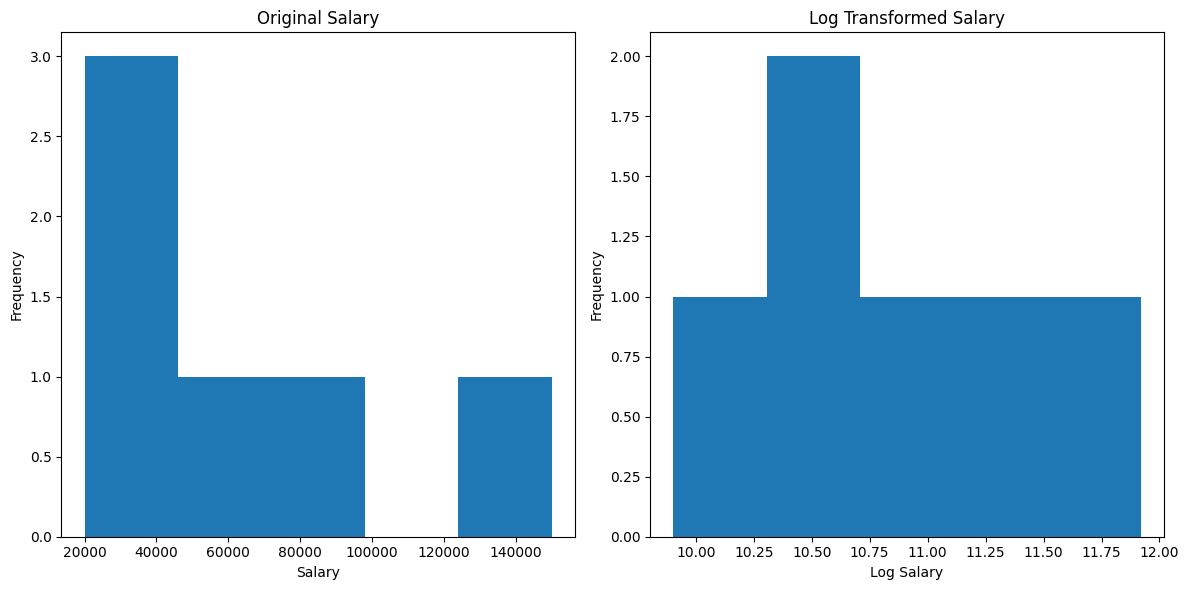

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.hist(df["Salary"], bins=5)
plt.title("Original Salary")
plt.xlabel("Salary")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.hist(df_log["Salary_log"], bins=5)
plt.title("Log Transformed Salary")
plt.xlabel("Log Salary")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()